**Cell 1: Kết nối Google Drive, Cài thư viện & Thiết lập đường dẫn chuẩn**

In [6]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q transformers accelerate sentencepiece protobuf scikit-learn

import os, sys, glob, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from transformers import AutoModelForSequenceClassification, get_cosine_schedule_with_warmup
from sklearn.metrics import f1_score, classification_report, multilabel_confusion_matrix

PROJECT_DIR = "/content/drive/MyDrive/DoAnCuoiKy-NLP"
os.makedirs(f"{PROJECT_DIR}/src", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/checkpoints", exist_ok=True)
os.chdir(PROJECT_DIR)
sys.path.append(PROJECT_DIR)

DRIVE_SAVE_DIR = f"{PROJECT_DIR}/checkpoints"

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị đang chạy:", device)
print("Thư mục làm việc hiện tại:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thiết bị đang chạy: cuda
Thư mục làm việc hiện tại: /content/drive/MyDrive/DoAnCuoiKy-NLP


**Cell 2: Ghi file src/transformer_dataset.py vào Drive**

In [7]:
%%writefile /content/drive/MyDrive/DoAnCuoiKy-NLP/src/transformer_dataset.py
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer

class TransformerToxicDataset(Dataset):
    """Dataset PyTorch hỗ trợ cả PhoBERT và ViDeBERTa cho bài toán đa nhãn."""
    def __init__(
        self,
        csv_path: str,
        tokenizer,
        model_name: str,
        max_len: int = 128,
        label_cols: list = ["toxic", "hate", "spam", "clean"]
    ):
        self.df = pd.read_csv(csv_path, encoding="utf-8")
        raw_texts = self.df["text_processed"].fillna("").astype(str).tolist()

        if "videberta" in model_name.lower():
            self.texts = [t.replace("_", " ") for t in raw_texts]
        else:
            self.texts = raw_texts

        self.labels = self.df[label_cols].values.astype("float32")
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=self.max_len,
            padding="max_length",
            return_tensors="pt"
        )
        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.float32)
        }

def create_transformer_dataloaders(
    model_name: str,
    train_path: str,
    val_path: str,
    test_path: str,
    max_len: int = 128,
    batch_size: int = 16
):
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    train_dataset = TransformerToxicDataset(train_path, tokenizer, model_name, max_len)
    val_dataset = TransformerToxicDataset(val_path, tokenizer, model_name, max_len)
    test_dataset = TransformerToxicDataset(test_path, tokenizer, model_name, max_len)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    return tokenizer, train_loader, val_loader, test_loader

Overwriting /content/drive/MyDrive/DoAnCuoiKy-NLP/src/transformer_dataset.py


**Cell 3: Tự động dò tìm dữ liệu train.csv, val.csv, test.csv & Tạo DataLoader**

In [8]:
import os
from src.transformer_dataset import create_transformer_dataloaders

DATA_DIR = "/content/drive/MyDrive/DoAnCuoiKy-NLP/processed"

# Kiểm tra chính xác tên các file đang nằm trong thư mục processed
if not os.path.exists(DATA_DIR):
    raise FileNotFoundError(
        f"Chưa thấy thư mục {DATA_DIR}. "
        "Bạn vào Google Drive -> 'Shared with me' -> chuột phải vào 'DoAnCuoiKy-NLP' -> Organize -> 'Add shortcut to Drive' nhé!"
    )

files = os.listdir(DATA_DIR)
print("Các file đang có trong processed:", files)

# Tự động khớp tên file train, val, test (kể cả khi tên là train_processed.csv hay train.csv)
train_file = [f for f in files if "train" in f.lower() and f.endswith(".csv")][0]
val_file   = [f for f in files if "val" in f.lower() and f.endswith(".csv")][0]
test_file  = [f for f in files if "test" in f.lower() and f.endswith(".csv")][0]

MODEL_NAME = "Fsoft-AIC/videberta-base"
LABEL_COLS = ["toxic", "hate", "spam", "clean"]
BATCH_SIZE = 16
MAX_LEN = 128

tokenizer, train_loader, val_loader, test_loader = create_transformer_dataloaders(
    model_name=MODEL_NAME,
    train_path=f"{DATA_DIR}/{train_file}",
    val_path=f"{DATA_DIR}/{val_file}",
    test_path=f"{DATA_DIR}/{test_file}",
    max_len=MAX_LEN,
    batch_size=BATCH_SIZE
)

print(f"Đã nạp thành công ({train_file}, {val_file}, {test_file}) -> Train: {len(train_loader)} batches | Val: {len(val_loader)} batches | Test: {len(test_loader)} batches")

Các file đang có trong processed: ['test.csv', 'train.csv', 'val.csv']
Đã nạp thành công (train.csv, val.csv, test.csv) -> Train: 1999 batches | Val: 250 batches | Test: 250 batches


**Cell 4: Khởi tạo Mô hình ViDeBERTa (float32), Optimizer & Sanity Check**

In [9]:
EPOCHS = 4
LR = 2e-5

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_COLS)
).to(device).float()

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)

total_steps = len(train_loader) * EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer, num_warmup_steps=int(0.1 * total_steps), num_training_steps=total_steps
)

def evaluate_transformer(model, loader, device, thresholds=None):
    model.eval()
    all_probs, all_targets = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            probs = torch.sigmoid(logits).cpu().numpy()
            all_probs.append(probs)
            all_targets.append(np.nan_to_num(batch["labels"].numpy(), nan=0.0))

    all_probs = np.vstack(all_probs)
    all_targets = np.vstack(all_targets)

    if thresholds is None:
        all_preds = (all_probs >= 0.5).astype(int)
    else:
        all_preds = np.zeros_like(all_probs, dtype=int)
        for i, th in enumerate(thresholds):
            all_preds[:, i] = (all_probs[:, i] >= th).astype(int)

    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    return macro_f1, all_targets, all_preds, all_probs

sample_batch = next(iter(train_loader))
with torch.no_grad():
    sample_logits = model(
        input_ids=sample_batch["input_ids"].to(device),
        attention_mask=sample_batch["attention_mask"].to(device)
    ).logits
    sample_loss = criterion(sample_logits, torch.nan_to_num(sample_batch["labels"].to(device), nan=0.0))

print(f"Sanity Check Batch 1 -> Loss: {sample_loss.item():.4f} | Có NaN không: {torch.isnan(sample_loss).item()}")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: Fsoft-AIC/videberta-base
Key                                        | Status     | 
-------------------------------------------+------------+-
mask_predictions.LayerNorm.bias            | UNEXPECTED | 
mask_predictions.classifier.bias           | UNEXPECTED | 
mask_predictions.classifier.weight         | UNEXPECTED | 
mask_predictions.dense.bias                | UNEXPECTED | 
deberta.embeddings.word_embeddings._weight | UNEXPECTED | 
mask_predictions.LayerNorm.weight          | UNEXPECTED | 
mask_predictions.dense.weight              | UNEXPECTED | 
classifier.weight                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those pa

Sanity Check Batch 1 -> Loss: 0.6938 | Có NaN không: False


**Cell 5: Huấn luyện 4 Epochs & Lưu Trọng số Tốt Nhất vào Drive**

In [10]:
import os

DRIVE_SAVE_DIR = "/content/drive/MyDrive/DoAnCuoiKy-NLP/checkpoints"
os.makedirs(DRIVE_SAVE_DIR, exist_ok=True)
DRIVE_CKPT = f"{DRIVE_SAVE_DIR}/videberta_best.pt"

best_val_f1 = -1.0
history = {"train_loss": [], "val_macro_f1": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = torch.nan_to_num(batch["labels"].to(device), nan=0.0)

        optimizer.zero_grad()
        logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    val_f1, _, _, val_probs = evaluate_transformer(model, val_loader, device)
    history["train_loss"].append(avg_loss)
    history["val_macro_f1"].append(val_f1)

    print(f"Epoch {epoch}/{EPOCHS} | Train Loss: {avg_loss:.4f} | Val Macro-F1 (th=0.5): {val_f1:.4f} | Prob [Min/Max]: {val_probs.min():.2f}/{val_probs.max():.2f}")

    if val_f1 >= best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), DRIVE_CKPT)
        print(f"  --> Đã lưu trọng số tốt nhất (Val Macro-F1: {best_val_f1:.4f})")

Epoch 1/4 | Train Loss: 0.3221 | Val Macro-F1 (th=0.5): 0.2283 | Prob [Min/Max]: 0.00/0.88
  --> Đã lưu trọng số tốt nhất (Val Macro-F1: 0.2283)
Epoch 2/4 | Train Loss: 0.2915 | Val Macro-F1 (th=0.5): 0.2283 | Prob [Min/Max]: 0.00/0.87
  --> Đã lưu trọng số tốt nhất (Val Macro-F1: 0.2283)
Epoch 3/4 | Train Loss: 0.2881 | Val Macro-F1 (th=0.5): 0.2283 | Prob [Min/Max]: 0.00/0.90
  --> Đã lưu trọng số tốt nhất (Val Macro-F1: 0.2283)
Epoch 4/4 | Train Loss: 0.2789 | Val Macro-F1 (th=0.5): 0.2283 | Prob [Min/Max]: 0.00/0.91
  --> Đã lưu trọng số tốt nhất (Val Macro-F1: 0.2283)


**Cell 6: Tối ưu Ngưỡng & Đánh giá trên Tập Test + Vẽ Ma trận Nhầm lẫn**

=== TỐI ƯU NGƯỠNG QUYẾT ĐỊNH TRÊN VALIDATION ===
  - Nhãn toxic : Ngưỡng tối ưu = 0.15 | Val F1 = 0.1265
  - Nhãn hate  : Ngưỡng tối ưu = 0.15 | Val F1 = 0.0581
  - Nhãn spam  : Ngưỡng tối ưu = 0.50 | Val F1 = 0.0000
  - Nhãn clean : Ngưỡng tối ưu = 0.80 | Val F1 = 0.9139

=== KẾT QUẢ VIDEBERTA-BASE TRÊN TẬP TEST (Macro-F1: 0.2657) ===

              precision    recall  f1-score   support

       toxic       0.49      0.07      0.12       637
        hate       0.56      0.02      0.03       326
        spam       0.00      0.00      0.00         0
       clean       0.84      1.00      0.91      3361

   micro avg       0.84      0.79      0.81      4324
   macro avg       0.47      0.27      0.27      4324
weighted avg       0.77      0.79      0.73      4324
 samples avg       0.84      0.85      0.84      4324



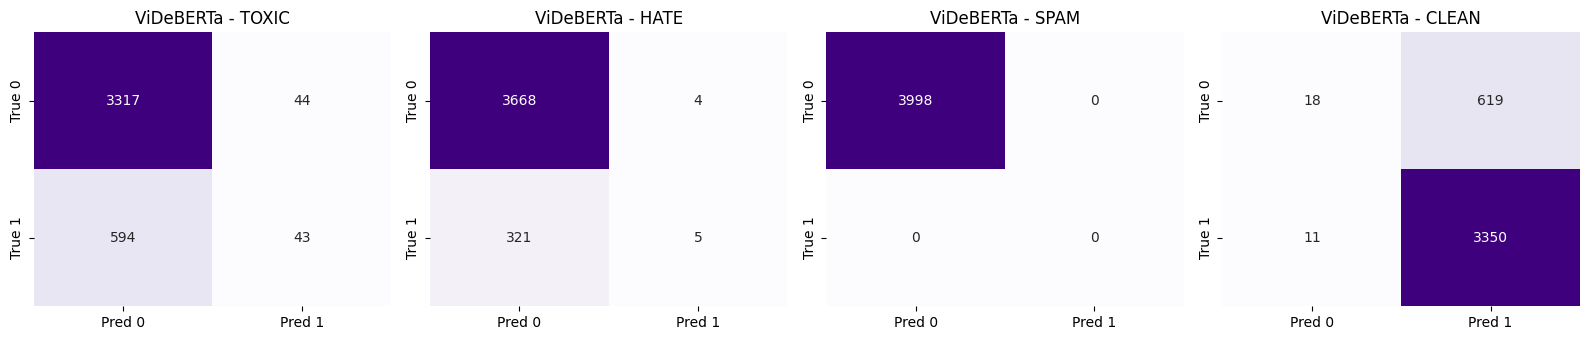

In [11]:
model.load_state_dict(torch.load(DRIVE_CKPT, map_location=device))
_, val_targets, _, val_probs = evaluate_transformer(model, val_loader, device)

best_thresholds = []
print("=== TỐI ƯU NGƯỠNG QUYẾT ĐỊNH TRÊN VALIDATION ===")
for i, label in enumerate(LABEL_COLS):
    best_th, best_label_f1 = 0.5, 0.0
    for th in np.arange(0.15, 0.81, 0.05):
        preds_i = (val_probs[:, i] >= th).astype(int)
        score = f1_score(val_targets[:, i], preds_i, zero_division=0)
        if score > best_label_f1:
            best_label_f1 = score
            best_th = round(float(th), 2)
    best_thresholds.append(best_th)
    print(f"  - Nhãn {label:<6}: Ngưỡng tối ưu = {best_th:.2f} | Val F1 = {best_label_f1:.4f}")

os.makedirs("configs", exist_ok=True)
with open("configs/videberta_thresholds.json", "w", encoding="utf-8") as f:
    json.dump(dict(zip(LABEL_COLS, best_thresholds)), f, indent=2)

test_f1, y_true, y_pred, y_probs = evaluate_transformer(model, test_loader, device, thresholds=best_thresholds)
print(f"\n=== KẾT QUẢ VIDEBERTA-BASE TRÊN TẬP TEST (Macro-F1: {test_f1:.4f}) ===\n")
print(classification_report(y_true, y_pred, target_names=LABEL_COLS, zero_division=0))

os.makedirs("assets", exist_ok=True)
mcm = multilabel_confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for idx, (matrix, label) in enumerate(zip(mcm, LABEL_COLS)):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Purples", cbar=False, ax=axes[idx],
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
    axes[idx].set_title(f"ViDeBERTa - {label.upper()}")

plt.tight_layout()
plt.savefig("assets/videberta_confusion_matrices.png", dpi=150)
plt.show()

**Cell 6: Đánh giá trên Tập Test & Vẽ Biểu đồ Ma trận Nhầm lẫn**

=== KẾT QUẢ VIDEBERTA-BASE TRÊN TẬP TEST (Macro-F1: 0.2657) ===

              precision    recall  f1-score   support

       toxic       0.49      0.07      0.12       637
        hate       0.56      0.02      0.03       326
        spam       0.00      0.00      0.00         0
       clean       0.84      1.00      0.91      3361

   micro avg       0.84      0.79      0.81      4324
   macro avg       0.47      0.27      0.27      4324
weighted avg       0.77      0.79      0.73      4324
 samples avg       0.84      0.85      0.84      4324



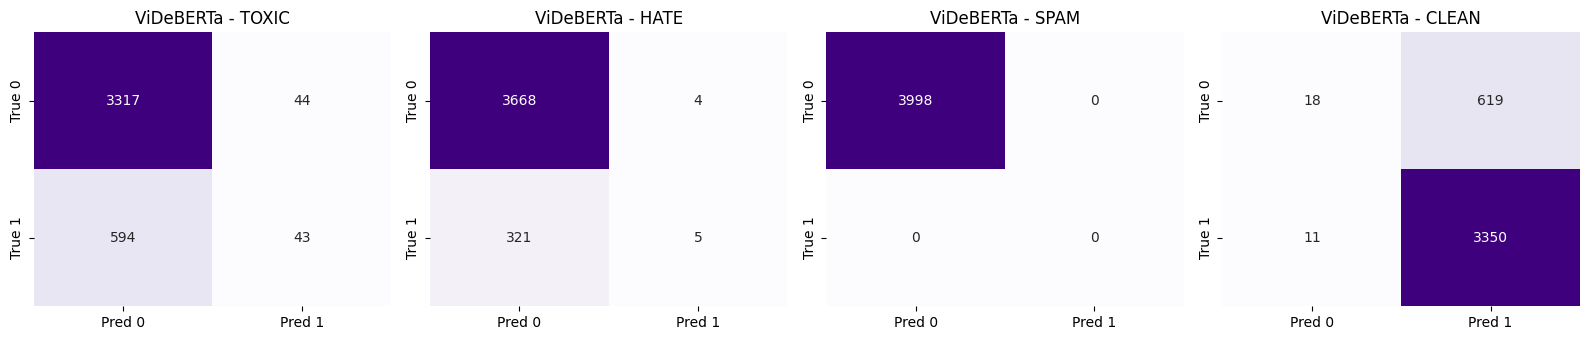

In [12]:
test_f1, y_true, y_pred, y_probs = evaluate_transformer(model, test_loader, device, thresholds=best_thresholds)

print(f"=== KẾT QUẢ VIDEBERTA-BASE TRÊN TẬP TEST (Macro-F1: {test_f1:.4f}) ===\n")
print(classification_report(y_true, y_pred, target_names=LABEL_COLS, zero_division=0))

os.makedirs("assets", exist_ok=True)
mcm = multilabel_confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for idx, (matrix, label) in enumerate(zip(mcm, LABEL_COLS)):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Purples", cbar=False, ax=axes[idx],
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
    axes[idx].set_title(f"ViDeBERTa - {label.upper()}")

plt.tight_layout()
plt.savefig("assets/videberta_confusion_matrices.png", dpi=150)
plt.show()